## This method does not predict a rating! it learns to rank by assigning a ranking score (dot product between latent user and item)

## How predicitions for know users work:
- (users in the train or test set) 
- get the user id 
- rank all the items for this user - calculate score
- filter the reviewed item_matrix to just the items from test set (or train if evaluating train)
- sort the list of items by the score for that user
- output top k

## For users not in train/test with some review:
- construct the features as before + the identity matrix - concat them
- predict the scores for items as before
- there is not much difference for new user since the method is more heavily item based

## We can calculate similarity using the latent representation of the user that the model is getting



## THE MODEL OUTPUTS SCORE BASED ON THE DOT PRODUCT OF ANY USER-ITEM PAIR IN THE LATENT REPRESENTATION!!! (+ bias :D)
- it the ranks based on this latent score!
- Hence learning is all about learning that trasnform into a space where similarity between user and item facilitates ranking procedure!



## HYbrid because it compares that property of Matrix Factorization with ability to tackle unseen users.
- We may not have ratings between user and item. BUT WE HAVE SIMILARITY IN LATENT SPACE!!!!!
- Therefore we can predict for out of distribution users or items - assum ing same feature formating


# Model Training

In [15]:
import pandas as pd
import numpy as np

In [2]:
ratings_full = pd.read_csv('../data/processed_full/user_item_processed_data.csv')
user_df = pd.read_csv('../data/processed_full/user_features.csv')
item_df = pd.read_csv('../data/processed_full/item_features.csv')

print("Data simulation complete.")
print("\nRatings Full DF shape:", ratings_full.shape)
print("\nItem Features DF shape:", item_df.shape)
print("\nUser Features DF shape:", user_df.shape)
ratings_full.head(5)

Data simulation complete.

Ratings Full DF shape: (1400102, 109)

Item Features DF shape: (27197, 115)

User Features DF shape: (46660, 115)


,user_id,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,text_emb_0,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,1521,19,1.0,NaN,1.0,NaN,1.0,1.0,NaN,-0.041622,...,0.051783,0.090821,0.023550,-0.028458,0.022709,-0.017830,0.030984,-0.066530,-0.004420,0.022615
1,1524,19,1.0,NaN,NaN,1.0,1.0,NaN,0.6,0.094268,...,0.007869,-0.021458,-0.011069,0.033729,-0.014652,0.031356,0.019260,-0.038565,-0.017441,0.011813
2,1527,19,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.226007,...,0.035656,0.022072,0.031577,-0.085225,-0.019208,0.009750,-0.041887,0.036383,0.069358,0.071002
3,1529,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.026531,...,0.003374,0.041171,0.008375,0.020658,0.000111,-0.012515,-0.019410,-0.014252,0.023997,0.030726
4,1530,19,0.8,NaN,NaN,NaN,NaN,NaN,NaN,0.133377,...,-0.012842,-0.004858,0.077540,-0.057574,0.024631,-0.011781,-0.032293,-0.060140,0.048414,0.012466


In [3]:
item_df.head(5)

,item_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_ratings,corr_rating_sleep quality,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,19,0.763636,0.843478,0.723810,0.800000,0.806250,0.888889,0.580000,0.046025,0.671665,...,0.014901,0.026970,0.020699,-0.023077,-0.004417,0.010669,0.001858,-0.008007,0.015665,0.010824
1,22,0.832000,0.885714,0.853333,0.800000,0.827273,0.907692,0.783333,0.026151,0.831531,...,-0.003962,0.002048,0.013580,0.005558,-0.015846,0.022196,-0.001296,-0.006309,0.011953,0.003244
2,23,0.805556,0.740000,0.768421,0.826087,0.840000,0.857143,0.827273,0.037657,0.753385,...,-0.010368,0.000376,0.010892,-0.016043,0.011998,0.011799,-0.005985,0.008956,-0.002391,0.008416
3,37,0.770000,0.781818,0.785714,0.690909,0.833333,0.866667,0.850000,0.020921,0.460283,...,0.013826,0.006809,0.005799,-0.017064,-0.003811,0.005202,-0.001809,-0.009861,-0.004628,-0.012835
4,43,0.843478,0.866667,0.800000,0.909091,0.952941,0.927273,0.885714,0.024059,0.288675,...,0.009699,0.010419,0.002312,0.010667,0.009719,-0.003631,-0.013600,0.003903,-0.007008,0.024912


In [4]:
user_df.head(5)

,user_id,rating,sleep quality,value,rooms,service,cleanliness,location,num_rated_items,corr_rating_sleep quality,...,text_emb_90,text_emb_91,text_emb_92,text_emb_93,text_emb_94,text_emb_95,text_emb_96,text_emb_97,text_emb_98,text_emb_99
0,8,0.993750,1.000000,1.000000,1.000000,0.993548,1.000000,0.983333,0.003241,NaN,...,-0.013878,-0.002051,0.011432,-0.004151,-0.002034,-0.019433,-0.007476,-0.004459,0.003242,0.004993
1,12,0.837500,0.800000,0.855556,0.850000,0.922581,0.980000,0.944444,0.003241,0.824589,...,0.007225,-0.004761,0.006946,-0.000852,0.008241,0.000151,0.007699,-0.003459,-0.002650,-0.017329
2,23,0.785185,0.773333,0.777778,0.750000,0.815385,0.846154,0.928571,0.002735,0.837389,...,-0.008082,0.004488,-0.004359,-0.002172,0.020979,-0.011370,0.005325,-0.004700,-0.013979,-0.003620
3,25,0.833333,0.850000,0.830769,0.857143,0.837037,0.855556,0.871429,0.004254,0.382971,...,-0.008281,0.003502,-0.011688,0.002253,0.002044,0.008348,-0.003149,-0.004344,0.007763,0.009010
4,26,0.752381,0.785714,0.722222,0.781818,0.676190,0.737500,0.815385,0.002127,0.836425,...,-0.012055,-0.020730,-0.008691,-0.009486,-0.015362,0.009323,-0.010816,0.002655,-0.000484,-0.002226


In [3]:
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix, csr_matrix, hstack
from lightfm import LightFM
from lightfm.cross_validation import random_train_test_split
from lightfm.evaluation import precision_at_k, auc_score

/Users/maksiuuuuuuu/miniconda3/envs/recsys_env/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [4]:
print("\n--- Step 1: Preprocessing Data ---")

# Handle NaN values in feature dataframes using mean imputation
# For item features
item_feature_cols = item_df.columns[1:] # all columns except item_id
for col in item_feature_cols:
    mean_val = item_df[col].mean()
    item_df[col].fillna(mean_val, inplace=True)

# For user features
user_feature_cols = user_df.columns[1:] # all columns except user_id
for col in user_feature_cols:
    mean_val = user_df[col].mean()
    user_df[col].fillna(mean_val, inplace=True)

print("NaNs in feature dataframes handled.")

# Create User and Item ID Mappings to internal indices
# This is crucial as LightFM needs 0-based consecutive integer indices.
unique_user_ids = sorted(ratings_full['user_id'].unique())
unique_item_ids = sorted(ratings_full['item_id'].unique())

user_id_map = {id: i for i, id in enumerate(unique_user_ids)}
item_id_map = {id: i for i, id in enumerate(unique_item_ids)}

# Create reverse mappings to convert predictions back to original IDs
inv_user_id_map = {i: id for id, i in user_id_map.items()}
inv_item_id_map = {i: id for id, i in item_id_map.items()}

# Apply mapping to the ratings dataframe
ratings_full['user_idx'] = ratings_full['user_id'].map(user_id_map)
ratings_full['item_idx'] = ratings_full['item_id'].map(item_id_map)

print("ID to Index mapping complete.")


--- Step 1: Preprocessing Data ---
NaNs in feature dataframes handled.
ID to Index mapping complete.


/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_1105/2959555610.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  item_df[col].fillna(mean_val, inplace=True)
/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_1105/2959555610.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [5]:
print("\n--- Step 2: Building LightFM Input Matrices ---")

# 1. Interaction Matrix
# We use the ratings as weights. A higher rating means a stronger positive interaction.
interactions = coo_matrix((ratings_full['rating'],
                           (ratings_full['user_idx'], ratings_full['item_idx'])),
                          shape=(len(user_id_map), len(item_id_map)))

print("Interaction matrix created.")

# 2. Item Feature Matrix
# We combine the "identity" of the item with its metadata.
# First, create the metadata features matrix
item_df_sorted = item_df.set_index('item_id').loc[unique_item_ids] # Ensure order matches mapping
item_features_meta = csr_matrix(item_df_sorted.values)

# Then, create the item identity matrix
item_features_identity = csr_matrix(np.identity(len(item_id_map)))

# Combine them horizontally
item_features = hstack([item_features_identity, item_features_meta])

print("Item features matrix created. Shape:", item_features.shape)


# 3. User Feature Matrix
# Similarly, combine user identity with metadata
user_df_sorted = user_df.set_index('user_id').loc[unique_user_ids] # Ensure order
user_features_meta = csr_matrix(user_df_sorted.values)

# User identity matrix
user_features_identity = csr_matrix(np.identity(len(user_id_map)))

# Combine them
user_features = hstack([user_features_identity, user_features_meta])

print("User features matrix created. Shape:", user_features.shape)


--- Step 2: Building LightFM Input Matrices ---
Interaction matrix created.
Item features matrix created. Shape: (27197, 27311)
User features matrix created. Shape: (46660, 46774)


In [6]:
print("\n--- Step 3: Training the LightFM Model ---")

# Split data into training and testing sets
train_interactions, test_interactions = random_train_test_split(
    interactions, test_percentage=0.2, random_state=np.random.RandomState(42)
)

# Instantiate the model
# WARP (Weighted Approximate-Rank Pairwise) is a good loss function for ranking.
model = LightFM(loss='warp',
                random_state=42,
                learning_rate=0.01,
                no_components=256,
                user_alpha=1e-5,    # User regularization
                item_alpha=1e-5     # Item regularization
                ) # Number of latent factors

# Train the model
# We pass the full feature sets, as they are used to represent users/items in both train and test.
model.fit(train_interactions,
          user_features=user_features,
          item_features=item_features,
          epochs=75,
          num_threads=12,
          verbose=True)

print("\nModel training complete.")


--- Step 3: Training the LightFM Model ---


Epoch: 100%|██████████| 75/75 [5:25:47<00:00, 260.64s/it]  


Model training complete.


In [7]:
import pickle

# Bundle everything needed for inference
checkpoint = {
    'model': model,
    'user_id_map': user_id_map,       # Map: UserID -> 123
    'item_id_map': item_id_map,       # Map: ItemID -> 456
    'inv_user_id_map': inv_user_id_map, # Map: 123 -> UserID
    'inv_item_id_map': inv_item_id_map, # Map: 456 -> ItemID
    'user_features': user_features,   # The sparse matrix used for training
    'item_features': item_features,   # The sparse matrix used for training
    'item_feature_shape': item_features.shape, # Useful for validation
    'user_feature_shape': user_features.shape,
    'train_interactions': train_interactions,# save the train and test interactions too
    'test_interactions': test_interactions
}

# Save to disk
with open('lightfm_hybrid_model_75e_256d.pkl', 'wb') as f:
    pickle.dump(checkpoint, f)

print("Model and artifacts saved successfully!")

Model and artifacts saved successfully!


In [5]:
import pickle

# load the model
with open('lightfm_hybrid_model_75e_256d.pkl', 'rb') as f:
    loaded_checkpoint = pickle.load(f)
    
model = loaded_checkpoint['model']
user_id_map = loaded_checkpoint['user_id_map']
item_id_map = loaded_checkpoint['item_id_map']
inv_user_id_map = loaded_checkpoint['inv_user_id_map']
inv_item_id_map = loaded_checkpoint['inv_item_id_map']
user_features = loaded_checkpoint['user_features']
item_features = loaded_checkpoint['item_features']
train_interactions = loaded_checkpoint['train_interactions']
test_interactions = loaded_checkpoint['test_interactions']

In [9]:
import time
from tqdm import tqdm
from collections import defaultdict

k_values = [10, 20, 50, 100]
train_interactions_csr = train_interactions.tocsr()
test_interactions_csr = test_interactions.tocsr()

# Pre-calculate true items for test users (as you did)
true_items_per_user = {
    u: dict(zip(test_interactions_csr[u].indices, test_interactions_csr[u].data))
    for u in range(test_interactions_csr.shape[0]) if test_interactions_csr[u].nnz > 0
}

test_user_indices = list(true_items_per_user.keys())
all_item_indices = np.arange(len(item_id_map))

# --- Accumulators for Metrics ---
ndcg_scores = {k: [] for k in k_values}
hit_counts = {k: 0 for k in k_values}
unique_items_recommended = {k: set() for k in k_values}
recommendation_counts = {k: defaultdict(int) for k in k_values} # For Diversity
total_users_evaluated = 0

In [9]:
from tqdm import tqdm
# --- Batch Processing ---
batch_size = 512 # Higher is faster, but uses more RAM
start_time = time.time()

print(f"Starting evaluation on {len(test_user_indices)} users...")

for start_idx in tqdm(range(0, len(test_user_indices), batch_size)):
    end_idx = start_idx + batch_size
    batch_users = test_user_indices[start_idx:end_idx]
    
    # 1. Predict Batch
    # Reshape logic is correct: repeat users, tile items
    ids_u = np.repeat(batch_users, len(all_item_indices))
    ids_i = np.tile(all_item_indices, len(batch_users))
    
    scores = model.predict(
        ids_u, ids_i, 
        user_features=user_features, 
        item_features=item_features
    )
    
    # Reshape to (n_users_in_batch, n_items)
    batch_scores = scores.reshape(len(batch_users), len(all_item_indices))
    
    # 2. MASK TRAINING ITEMS (Critical Step!)
    # We set scores of items present in training data to -infinity
    for i, user_idx in enumerate(batch_users):
        # Get item indices this user interacted with in TRAIN
        train_items = train_interactions_csr[user_idx].indices
        # Set their score to negative infinity so they are never recommended
        batch_scores[i, train_items] = -np.inf

    # 3. Get Top K indices (Sort once per batch)
    # We only need the top 100 (max k) to calculate all metrics
    max_k = max(k_values)
    
    # argpartition is faster than argsort for top-k, but argsort is safer for exact ranking order
    # stick to argsort for nDCG accuracy
    top_items_indices = np.argsort(-batch_scores, axis=1)[:, :max_k]

    # 4. Calculate Metrics
    for i, user_idx in enumerate(batch_users):
        true_items = true_items_per_user[user_idx]
        recs = top_items_indices[i] # Top 100 items for this user
        
        for k in k_values:
            top_k_recs = recs[:k]
            
            # -- nDCG --
            dcg = 0
            idcg = 0
            
            # DCG
            for rank, item in enumerate(top_k_recs):
                if item in true_items:
                    dcg += true_items[item] / np.log2(rank + 2)
            
            # IDCG (Ideal)
            sorted_true_scores = sorted(true_items.values(), reverse=True)
            for rank, score in enumerate(sorted_true_scores[:k]):
                idcg += score / np.log2(rank + 2)
            
            ndcg_val = (dcg / idcg) if idcg > 0 else 0
            ndcg_scores[k].append(ndcg_val)
            
            # -- Hit Rate --
            # Check if set intersection is not empty
            if not set(top_k_recs).isdisjoint(true_items.keys()):
                hit_counts[k] += 1
            
            # -- Coverage/Diversity Data Collection --
            for item in top_k_recs:
                unique_items_recommended[k].add(item)
                recommendation_counts[k][item] += 1

    total_users_evaluated += len(batch_users)

print(f"\nEvaluation complete in {time.time() - start_time:.2f}s")

Starting evaluation on 46455 users...


100%|██████████| 91/91 [1:22:59<00:00, 54.72s/it]


Evaluation complete in 4979.36s


In [10]:
# --- Final Calculations ---
ndcg_results = {}
hitrate_results = {}
coverage_results = {}
gini_results = {}

total_catalog_size = len(item_id_map) # Total unique items in your dataset

for k in k_values:
    print(f"\n--- K = {k} ---")
    
    # 1. nDCG
    mean_ndcg = np.mean(ndcg_scores[k])
    ndcg_results[k] = mean_ndcg
    print(f"nDCG: {mean_ndcg:.4f}")
    
    # 2. Hit Rate
    hit_rate = hit_counts[k] / total_users_evaluated
    hitrate_results[k] = hit_rate
    print(f"Hit Rate: {hit_rate:.4f}")
    
    # 3. Catalog Coverage
    # Percentage of items recommended at least once
    cov = len(unique_items_recommended[k]) / total_catalog_size
    coverage_results[k] = cov
    print(f"Coverage: {cov:.4f}")
    
    # 4. Diversity: Gini Coefficient (Inequality)
    # Step A: Create an array representing counts for EVERY item in the catalog
    # (Initialize with zeros so we account for items never recommended)
    all_item_counts = np.zeros(total_catalog_size)
    
    # Step B: Fill in the counts we observed
    for item_idx, count in recommendation_counts[k].items():
        all_item_counts[item_idx] = count
        
    # Step C: Sort counts (Required for Gini formula)
    sorted_counts = np.sort(all_item_counts)
    
    # Step D: Apply Gini Formula
    n = total_catalog_size
    cum_counts = np.cumsum(sorted_counts)
    
    # Standard Gini formula using ordered values:
    # G = (2 * sum(i * x_i) - (n + 1) * sum(x_i)) / (n * sum(x_i))
    # Or the numpy vector way:
    index = np.arange(1, n + 1)
    numerator = np.sum((2 * index - n - 1) * sorted_counts)
    denominator = n * np.sum(sorted_counts)
    
    if denominator == 0:
        gini = 0.0 # If no recommendations were made (edge case)
    else:
        gini = numerator / denominator
        
    gini_results[k] = gini
    print(f"Gini Coefficient: {gini:.4f} (Lower is Better/More Diverse)")


--- K = 10 ---
nDCG: 0.0263
Hit Rate: 0.1551
Coverage: 0.5227
Gini Coefficient: 0.9064 (Lower is Better/More Diverse)

--- K = 20 ---
nDCG: 0.0345
Hit Rate: 0.2413
Coverage: 0.6798
Gini Coefficient: 0.8784 (Lower is Better/More Diverse)

--- K = 50 ---
nDCG: 0.0495
Hit Rate: 0.3947
Coverage: 0.8664
Gini Coefficient: 0.8275 (Lower is Better/More Diverse)

--- K = 100 ---
nDCG: 0.0638
Hit Rate: 0.5320
Coverage: 0.9551
Gini Coefficient: 0.7754 (Lower is Better/More Diverse)


In [17]:
# # precision and recal for each k in  k_values
# from lightfm.evaluation import precision_at_k, recall_at_k

# precision_values = {}
# recall_values = {}
# for k in k_values:
#     precision = precision_at_k(model, test_interactions, user_features=user_features, item_features=item_features, k=k).mean()
#     recall = recall_at_k(model, test_interactions, user_features=user_features, item_features=item_features, k=k).mean()
#     precision_values[k] = precision
#     recall_values[k] = recall
#     print(f"Precision@{k}: {precision:.4f}, Recall@{k}: {recall:.4f}")

# # Print precision and recall results
# for k in k_values:
#     print(f"Precision@{k}: {precision_values[k]:.4f}")
#     print(f"Recall@{k}: {recall_values[k]:.4f}")

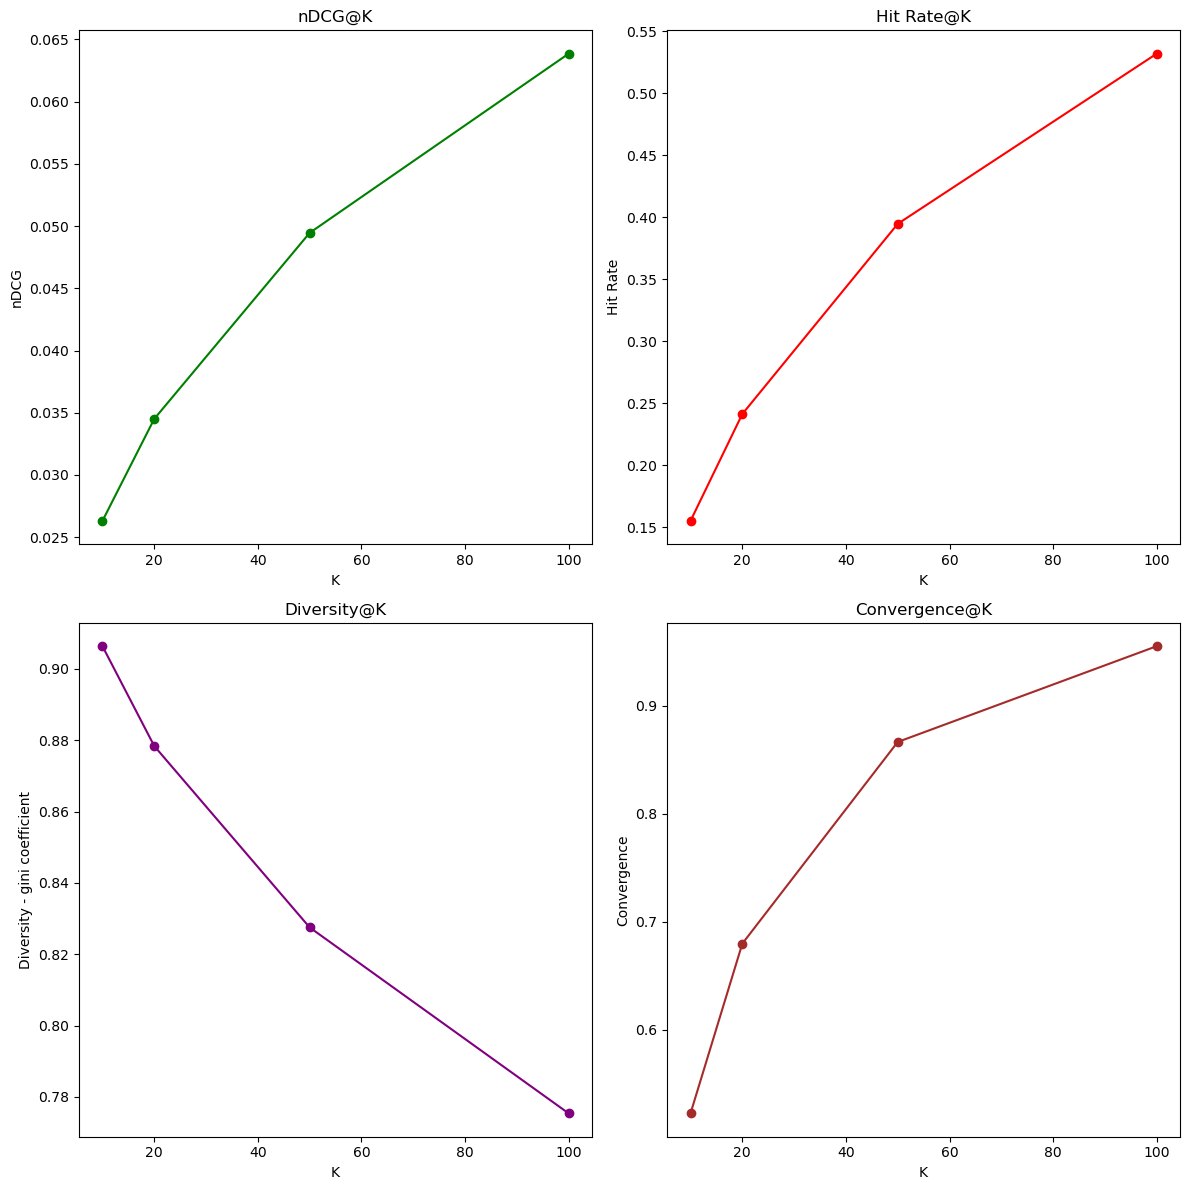

In [11]:
# plot precision_values, recall_values, ndcg_scores , hitrate_values, convergence_values, diveristy_values in subgraphs for k
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
axs[0, 0].plot(k_values, [ndcg_results[k] for k in k_values], marker='o', color='green')
axs[0, 0].set_title('nDCG@K')
axs[0, 0].set_xlabel('K')
axs[0, 0].set_ylabel('nDCG')
axs[0, 1].plot(k_values, [hitrate_results[k] for k in k_values], marker='o', color='red')  
axs[0, 1].set_title('Hit Rate@K')
axs[0, 1].set_xlabel('K')
axs[0, 1].set_ylabel('Hit Rate')
axs[1, 0].plot(k_values, [gini_results[k] for k in k_values], marker='o', color='purple')
axs[1, 0].set_title('Diversity@K')
axs[1, 0].set_xlabel('K')
axs[1, 0].set_ylabel('Diversity - gini coefficient')
axs[1, 1].plot(k_values, [coverage_results[k] for k in k_values], marker='o', color='brown')
axs[1, 1].set_title('Convergence@K')
axs[1, 1].set_xlabel('K')
axs[1, 1].set_ylabel('Convergence')
plt.tight_layout()
plt.show()

# Grouping

In [10]:
import seaborn as sns
import random
from scipy.special import expit # Sigmoid function

In [11]:
# --- CONFIGURATION ---
EVAL_POOL_SIZE = 5000   # Large enough to minimize group overlap
N_GROUPS_PER_SIZE = 1000 # Large enough for smooth Confidence Intervals
GROUP_SIZES = [4, 6, 8, 10, 12, 15]
TOP_K = 100

In [12]:
# 1. Select the pool of users
# We filter for users who actually exist in the test set mapping
valid_test_users = list(true_items_per_user.keys())

if len(valid_test_users) > EVAL_POOL_SIZE:
    # Randomly sample without replacement
    eval_user_ids = np.random.choice(valid_test_users, size=EVAL_POOL_SIZE, replace=False)
else:
    eval_user_ids = np.array(valid_test_users)

print(f"Preparing evaluation pool with {len(eval_user_ids)} users...")

Preparing evaluation pool with 5000 users...


In [13]:
# 2. Pre-calculate Scores (Batch Prediction)
# We predict for ALL items for these 5000 users at once.
# Memory usage: 5000 users * 27000 items * 4 bytes ~= 540 MB RAM. Safe.

user_indices_repeat = np.repeat(eval_user_ids, len(item_id_map))
item_indices_tile = np.tile(np.arange(len(item_id_map)), len(eval_user_ids))

print("Running batch prediction (this might take 30-60 seconds)...")
flat_scores = model.predict(
    user_indices_repeat, 
    item_indices_tile, 
    user_features=user_features, 
    item_features=item_features,
    num_threads=12
)

# Reshape to (n_users, n_items)
# Row i corresponds to user eval_user_ids[i]
precalc_scores = flat_scores.reshape(len(eval_user_ids), len(item_id_map))

Running batch prediction (this might take 30-60 seconds)...


In [27]:
# 3. Pre-calculate Training Masks
# We need to know which items each user has already seen to exclude them.
print("Building training masks...")
train_mask = np.zeros(precalc_scores.shape, dtype=bool)

# We need to map Real User ID -> Index in our precalc matrix (0 to 4999)
pool_id_to_index = {uid: i for i, uid in enumerate(eval_user_ids)}

for real_uid in eval_user_ids:
    matrix_idx = pool_id_to_index[real_uid]
    # Get items seen in training
    seen_items = train_interactions_csr[real_uid].indices
    train_mask[matrix_idx, seen_items] = True

print("Pre-calculation complete. Ready for Simulation.")

Building training masks...
Pre-calculation complete. Ready for Simulation.


In [28]:
def aggregate_scores(group_scores, strategy):
    """
    group_scores: (group_size, n_items) matrix of raw LightFM scores
    """
    n_items = group_scores.shape[1]
    
    if strategy == 'additive':
        # Average utility
        return np.mean(group_scores, axis=0)
    
    elif strategy == 'least_misery':
        # Maximize the minimum satisfaction in the group
        return np.min(group_scores, axis=0)
    
    elif strategy == 'multiplicative':
        # 1. Find Min and Max score for each user in the group
        # axis=1 ensures we look at the user's specific range across all items
        mins = np.min(group_scores, axis=1, keepdims=True)
        maxs = np.max(group_scores, axis=1, keepdims=True)
        
        # 2. Min-Max Normalize to range [0.01, 1.0]
        # We use 0.01 as the floor to strictly avoid log(0) issues without using an arbitrary epsilon
        # This converts "User's Worst Item" -> 0.01 and "User's Best Item" -> 1.0
        norm_scores = (group_scores - mins) / (maxs - mins + 1e-9)
        norm_scores = norm_scores * 0.99 + 0.01
        
        # 3. Sum of Logs (Equivalent to Product of Probabilities)
        return np.sum(np.log(norm_scores), axis=0)
    
    elif strategy == 'approval_voting':
        # 1. Determine Threshold per user
        # We define "Approval" as: Score > User's Mean Score for all items
        # This adapts to users who rate strictly vs leniently
        user_means = np.mean(group_scores, axis=1, keepdims=True)
        
        # 2. Cast Votes (1 if above mean, 0 otherwise)
        votes = (group_scores > user_means).astype(float)
        
        # 3. Sum Votes (Count approvals)
        approval_counts = np.sum(votes, axis=0)
        
        # 4. TIE BREAKER (Crucial!)
        # If two items both have 4 votes, the one with higher raw score sum should win.
        # We add a tiny fraction of the additive score.
        # Normalize raw scores to 0-1 range locally to avoid overpowering the vote count
        raw_sum = np.sum(group_scores, axis=0)
        raw_norm = (raw_sum - raw_sum.min()) / (raw_sum.max() - raw_sum.min() + 1e-9)
        
        return approval_counts + (0.01 * raw_norm)

    return np.mean(group_scores, axis=0)

# Group Eval

In [29]:
results = []
strategies = ['additive', 'multiplicative', 'approval_voting', 'least_misery']

print(f"Starting Simulation: {N_GROUPS_PER_SIZE} groups per size...")

for size in GROUP_SIZES:
    # Use tqdm to track progress
    for _ in tqdm(range(N_GROUPS_PER_SIZE), desc=f"Simulating Size {size}"):
        
        # 1. Sample Group
        # We pick indices from our pool (0 to 4999)
        group_pool_indices = np.random.choice(len(eval_user_ids), size=size, replace=False)
        group_real_ids = eval_user_ids[group_pool_indices]
        
        # 2. Extract Data
        # Shape: (size, n_items)
        group_scores = precalc_scores[group_pool_indices]
        group_masks = train_mask[group_pool_indices]
        
        # 3. Combined Mask (If ANYONE saw it, remove it)
        final_mask = np.any(group_masks, axis=0)
        
        for strat in strategies:
            # 4. Aggregate
            final_scores = aggregate_scores(group_scores, strat)
            
            # 5. Apply Mask (Block seen items)
            final_scores[final_mask] = -np.inf
            
            # 6. Get Top K Items
            # We need indices of the winners
            top_items = np.argsort(-final_scores)[:TOP_K]
            
            # 7. Evaluate (Group nDCG)
            # Calculate nDCG for each member individually, then average
            member_ndcgs = []
            
            for i, user_id in enumerate(group_real_ids):
                true_items = true_items_per_user[user_id]
                
                # Calculate nDCG for this member
                dcg = 0.0
                idcg = 0.0
                
                # DCG part
                for rank, item_idx in enumerate(top_items):
                    if item_idx in true_items:
                        dcg += true_items[item_idx] / np.log2(rank + 2)
                
                # IDCG part (Ideal ranking for this specific user)
                sorted_true = sorted(true_items.values(), reverse=True)
                for rank, val in enumerate(sorted_true[:TOP_K]):
                    idcg += val / np.log2(rank + 2)
                
                ndcg = (dcg / idcg) if idcg > 0 else 0.0
                member_ndcgs.append(ndcg)
            
            # 8. Store Result
            results.append({
                'Group_Size': size,
                'Strategy': strat,
                'nDCG': np.mean(member_ndcgs)
            })

# Create DataFrame
df_results = pd.DataFrame(results)
print("Simulation finished.")

Starting Simulation: 1000 groups per size...


Simulating Size 15: 100%|██████████| 1000/1000 [00:07<00:00, 131.47it/s]

Simulation finished.


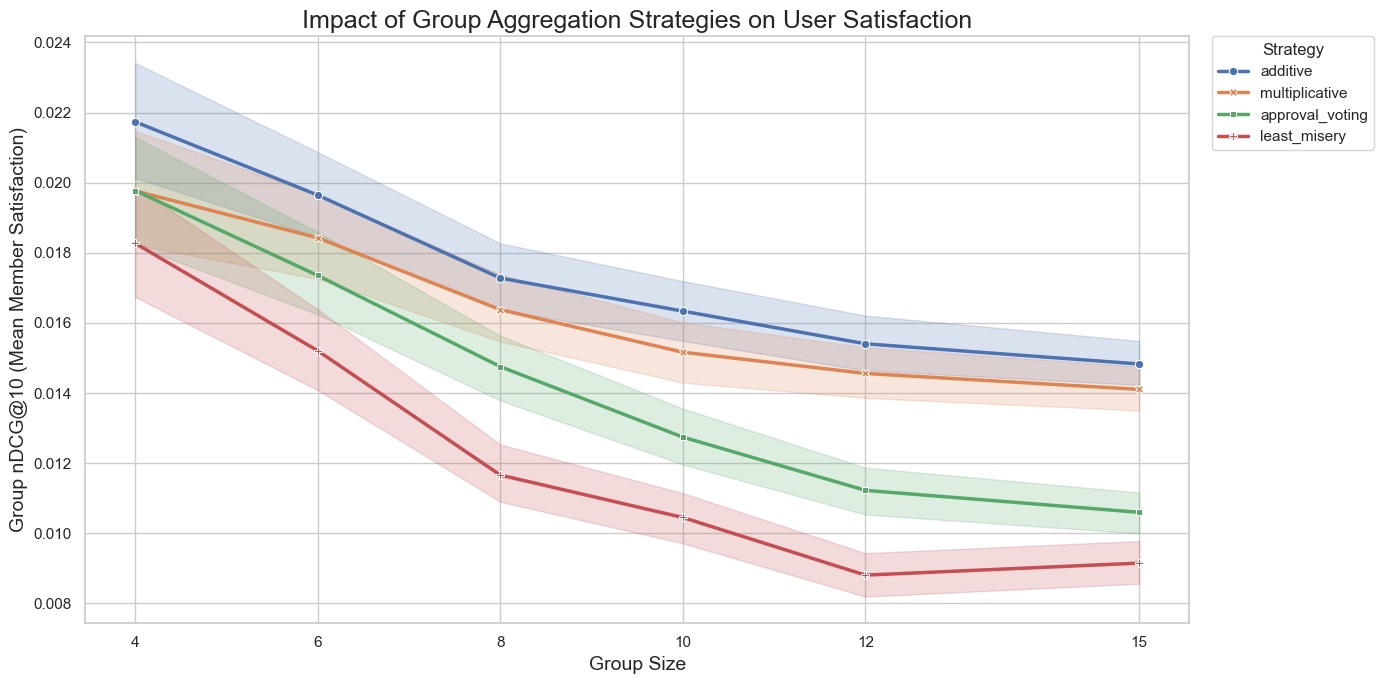


Detailed Statistical Summary:


mean       std  min       max
Group_Size Strategy                                          
4          additive         0.021736  0.026845  0.0  0.258960
           approval_voting  0.019775  0.025659  0.0  0.258960
           least_misery     0.018271  0.024687  0.0  0.134942
           multiplicative   0.019764  0.025071  0.0  0.205211
6          additive         0.019645  0.020453  0.0  0.152123
           approval_voting  0.017353  0.019758  0.0  0.152264
           least_misery     0.015206  0.018786  0.0  0.152575
           multiplicative   0.018427  0.019037  0.0  0.138184
8          additive         0.017280  0.015703  0.0  0.114700
           approval_voting  0.014753  0.015453  0.0  0.124477
           least_misery     0.011661  0.013437  0.0  0.120931
           multiplicative   0.016380  0.015310  0.0  0.113012
10         additive         0.016337  0.013584  0.0  0.083777
           approval_voting  0.012744  0.013043  0.0  0.074618
           least_misery     0.010451  0.011133  0.0  0.075892
           multiplicative   0.015165  0.013266  0.0  0.082480
12         additive         0.015405  0.012701  0.0  0.095242
           approval_voting  0.011225  0.011210  0.0  0.085196
           least_misery     0.008808  0.009470  0.0  0.059178
           multiplicative   0.014559  0.012125  0.0  0.093106
15         additive         0.014829  0.010297  0.0  0.062203
           approval_voting  0.010599  0.009431  0.0  0.058120
           least_misery     0.009150  0.009796  0.0  0.070144
           multiplicative   0.014105  0.009854  0.0  0.061423

In [30]:
# Set up plotting
sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(14, 7))

# Draw Box Plot + Swarm or simple Bar with Error Bars
# Using Lineplot is often cleaner for "Size vs Performance" comparison
ax = sns.lineplot(
    data=df_results, 
    x="Group_Size", 
    y="nDCG", 
    hue="Strategy",
    style="Strategy",
    markers=True,
    dashes=False,
    linewidth=2.5,
    errorbar=('ci', 95) # 95% Confidence Interval shading
)

plt.title("Impact of Group Aggregation Strategies on User Satisfaction", fontsize=18)
plt.ylabel("Group nDCG@100 (Mean Member Satisfaction)", fontsize=14)
plt.xlabel("Group Size", fontsize=14)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Strategy")
plt.xticks(GROUP_SIZES)
plt.tight_layout()
plt.show()

# --- Statistical Table ---
summary = df_results.groupby(['Group_Size', 'Strategy'])['nDCG'].describe()[['mean', 'std', 'min', 'max']]
print("\nDetailed Statistical Summary:")
display(summary)

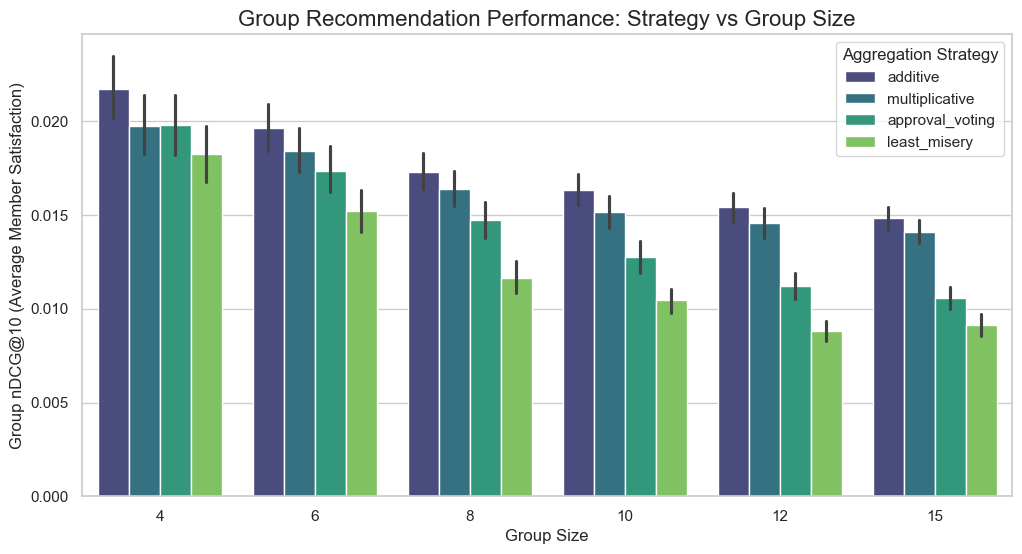


Mean nDCG Scores:


Strategy,additive,approval_voting,least_misery,multiplicative
Group_Size,,,,
4,0.021736,0.019775,0.018271,0.019764
6,0.019645,0.017353,0.015206,0.018427
8,0.017280,0.014753,0.011661,0.016380
10,0.016337,0.012744,0.010451,0.015165
12,0.015405,0.011225,0.008808,0.014559
15,0.014829,0.010599,0.009150,0.014105


In [31]:
# Set plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Create Barplot
# ci=95 draws the confidence intervals (error bars) automatically
ax = sns.barplot(
    data=df_results, 
    x="Group_Size", 
    y="nDCG", 
    hue="Strategy", 
    palette="viridis",
    errorbar=('ci', 95) 
)

plt.title("Group Recommendation Performance: Strategy vs Group Size", fontsize=16)
plt.ylabel("Group nDCG@10 (Average Member Satisfaction)", fontsize=12)
plt.xlabel("Group Size", fontsize=12)
plt.legend(title="Aggregation Strategy", loc='upper right')
plt.show()

# Print numerical summary
summary = df_results.groupby(['Group_Size', 'Strategy'])['nDCG'].mean().unstack()
print("\nMean nDCG Scores:")
display(summary)